In [ ]:
import pandas as pd

df = pd.read_csv("DogrusalRegresyon.csv")

df.head()

,Cinsiyet,Yas_Araligi,Bas_cevresi(cm^3),Beyin_agirligi(gr)
0,1,1,4512,1530
1,1,1,3738,1297
2,1,1,4261,1335
3,1,1,3777,1282
4,1,1,4177,1590


In [ ]:
print("Veri seti boyutu:", df.shape)

print("\nEksik değer sayıları:")
print(df.isnull().sum())

Veri seti boyutu: (237, 4)

Eksik değer sayıları:
Cinsiyet              0
Yas_Araligi           0
Bas_cevresi(cm^3)     0
Beyin_agirligi(gr)    0
dtype: int64


In [ ]:
X = df[["Bas_cevresi(cm^3)"]]
y = df["Beyin_agirligi(gr)"]

print("X:")
print(X.head())

print("\ny:")
print(y.head())

X:
   Bas_cevresi(cm^3)
0               4512
1               3738
2               4261
3               3777
4               4177

y:
0    1530
1    1297
2    1335
3    1282
4    1590
Name: Beyin_agirligi(gr), dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Eğitim veri sayısı:", len(X_train))
print("Test veri sayısı:", len(X_test))

Eğitim veri sayısı: 189
Test veri sayısı: 48


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

a = model.intercept_
b = model.coef_[0]

print("a (sabit terim):", a)
print("b (eğim):", b)

print(f"\nModel denklemi: Y = {a:.4f} + {b:.4f}X")

a (sabit terim): 328.6014118561542
b (eğim): 0.26188775888054894

Model denklemi: Y = 328.6014 + 0.2619X


In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Test verileri üzerinde tahmin
y_pred = model.predict(X_test)

# Performans metrikleri
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"R²: {r2:.4f}")
print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")

R²: 0.7149
MSE: 4672.0435
MAE: 54.6260


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


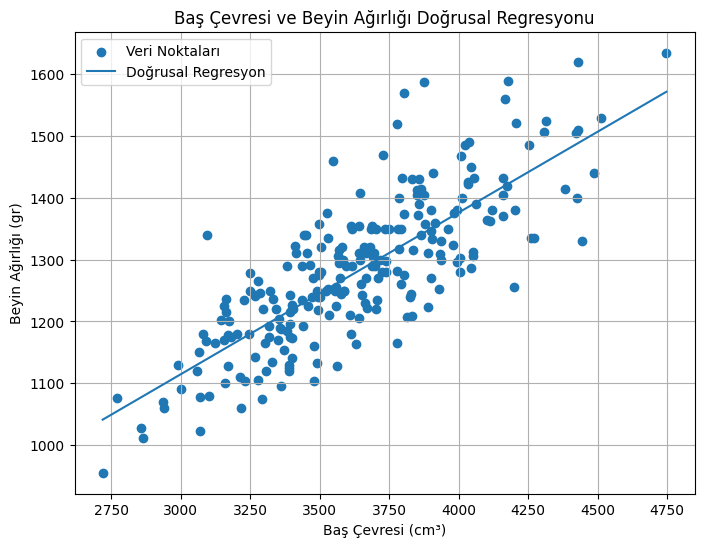

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Tüm X değerlerini küçükten büyüğe sıralayalım
X_sorted = np.sort(X.values.flatten())

# Regresyon doğrusu için tahminler
y_line = model.predict(X_sorted.reshape(-1, 1))

plt.figure(figsize=(8, 6))

# Veri noktaları
plt.scatter(
    X,
    y,
    label="Veri Noktaları"
)

# Regresyon doğrusu
plt.plot(
    X_sorted,
    y_line,
    label="Doğrusal Regresyon"
)

plt.xlabel("Baş Çevresi (cm³)")
plt.ylabel("Beyin Ağırlığı (gr)")
plt.title("Baş Çevresi ve Beyin Ağırlığı Doğrusal Regresyonu")
plt.legend()
plt.grid(True)

plt.show()